# 02 - Preparación de los datos para el modelado
**Proyecto 2 - CGIAR Eyes on the Ground**

En este notebook se define la tarea de clasificación, se agrupan las clases de daño y se hace la partición en train, validación y test. El resultado se guarda en `data/splits/split.csv` para que todos los modelos usen exactamente los mismos conjuntos.

## 1. Decisiones

- **Tarea:** clasificar el tipo de daño (`damage`) a partir de la imagen.
- **Experimento principal:** 4 clases (Bueno, Maleza, Sequía, Otro daño). Las cinco clases minoritarias (Enfermedad, Inundación, Deficiencia de nutrientes, Plaga y Viento) suman menos del 3% y varias tienen muy pocas fotos, así que se agrupan en "Otro daño".
- **Experimento secundario:** las 8 clases originales, con la misma partición.
- **Partición agrupada:** las fotos del mismo campo (mismo prefijo en el nombre de archivo) se mantienen juntas, para que el modelo no aprenda a reconocer el campo en vez del daño.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Funciona corriendo desde la raíz del proyecto o desde notebooks/
RAIZ = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.append(str(RAIZ))

from src.particion import mapear_clase4, asignar_grupos, particionar, verificar_particion

SEMILLA = 42
sns.set_theme(style="whitegrid")

## 2. Carga y agrupación de clases

In [2]:
train = pd.read_csv(RAIZ / "data" / "Train.csv")
train["clase4"] = mapear_clase4(train["damage"])

print(train.shape)
resumen = train["clase4"].value_counts().to_frame("conteo")
resumen["%"] = (resumen["conteo"] / len(train) * 100).round(1)
resumen

(26068, 7)


,conteo,%
clase4,,
Bueno,11623,44.6
Maleza,9238,35.4
Sequía,4516,17.3
Otro daño,691,2.7


In [3]:
# Qué clases originales quedaron dentro de "Otro daño"
train[train["clase4"] == "Otro daño"]["damage"].value_counts()

damage
ND    272
PS    254
DS    115
WN     37
FD     13
Name: count, dtype: int64

## 3. Grupos para la partición

Casi todos los nombres de archivo empiezan con un prefijo tipo `L427F01330`, que se repite en varias fotos. No se sabe con certeza qué representa cada parte del código, pero lo razonable es tratarlo como identificador de campo o parcela. Las fotos de LR2020 tienen otro formato (`24_initial_1_...`) y se agrupan por el número del inicio.

In [4]:
train["grupo"] = asignar_grupos(train)

fotos_por_grupo = train.groupby("grupo").size()
print("Grupos distintos:", fotos_por_grupo.shape[0])
print(fotos_por_grupo.describe()[["mean", "50%", "max"]].round(1).to_string())

Grupos distintos: 3114
mean     8.4
50%      6.0
max     60.0


## 4. Partición

In [5]:
train = particionar(train, semilla=SEMILLA)
verificar_particion(train)  # falla si algún grupo quedó en dos conjuntos

tamanos = train["split"].value_counts().to_frame("fotos")
tamanos["%"] = (tamanos["fotos"] / len(train) * 100).round(1)
tamanos.loc[["train", "val", "test"]]

,fotos,%
split,,
train,18620,71.4
val,3724,14.3
test,3724,14.3


In [6]:
# Distribución de las 4 clases en cada conjunto
pd.crosstab(train["clase4"], train["split"])[["train", "val", "test"]]

split,train,val,test
clase4,,,
Bueno,8302,1661,1660
Maleza,6600,1319,1319
Otro daño,492,99,100
Sequía,3226,645,645


In [7]:
# Las 8 clases originales: se revisa que las raras aparezcan en los tres conjuntos
pd.crosstab(train["damage"], train["split"])[["train", "val", "test"]]

split,train,val,test
damage,,,
DR,3226,645,645
DS,81,16,18
FD,9,2,2
G,8302,1661,1660
ND,194,39,39
PS,181,37,36
WD,6600,1319,1319
WN,27,5,5


In [8]:
# Temporadas por conjunto
pd.crosstab(train["season"], train["split"])[["train", "val", "test"]]

split,train,val,test
season,,,
LR2020,1490,227,316
LR2021,5650,1126,1169
SR2020,4433,919,811
SR2021,7047,1452,1428


Las clases raras (por ejemplo Inundación, con 13 fotos en total) quedan con muy pocos ejemplos en validación y test, así que sus métricas en el experimento de 8 clases van a ser ruidosas. Es una de las razones de usar 4 clases como experimento principal.

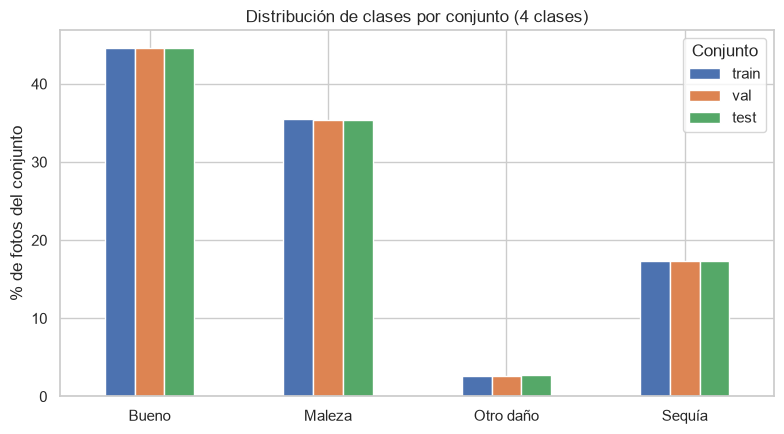

In [9]:
porcentaje = (pd.crosstab(train["clase4"], train["split"], normalize="columns") * 100)[["train", "val", "test"]]

fig, ax = plt.subplots(figsize=(8, 4.5))
porcentaje.plot(kind="bar", ax=ax, rot=0)
ax.set_ylabel("% de fotos del conjunto")
ax.set_xlabel("")
ax.set_title("Distribución de clases por conjunto (4 clases)")
ax.legend(title="Conjunto")
fig.tight_layout()

(RAIZ / "figuras").mkdir(exist_ok=True)
fig.savefig(RAIZ / "figuras" / "split_distribucion_4clases.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Guardar la partición

In [10]:
salida = RAIZ / "data" / "splits"
salida.mkdir(parents=True, exist_ok=True)

columnas = ["ID", "filename", "growth_stage", "season", "damage", "clase4", "extent", "grupo", "split"]
train[columnas].to_csv(salida / "split.csv", index=False)
print("Guardado en", salida / "split.csv")

Guardado en c:\Users\Emadlg\Desktop\UVG\Cuarto Año\Segundo Ciclo\Data Science\Data_Science\Proyecto2\data\splits\split.csv


## Siguiente paso

Preprocesar las imágenes (redimensionar y normalizar) y extraer embeddings con los modelos preentrenados, usando `split.csv` para saber qué foto va en cada conjunto.